# Potato Disease Classification

### Import all the Dependencies

In [1]:
import tensorflow as tf
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt
from IPython.display import HTML

### Set all the Constants

In [3]:
BATCH_SIZE = 32
IMAGE_SIZE = 256
CHANNELS=3
EPOCHS=50

### Import data into tensorflow dataset object

In [4]:
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "PlantVillage",
    seed=123,
    shuffle=True,
    image_size=(IMAGE_SIZE,IMAGE_SIZE),
    batch_size=BATCH_SIZE
)

Found 2152 files belonging to 3 classes.


In [6]:
class_names = dataset.class_names
class_names

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

In [7]:
for image_batch, labels_batch in dataset.take(1):
    print(image_batch.shape)
    print(labels_batch.numpy())

(32, 256, 256, 3)
[1 1 1 0 0 0 0 0 1 1 1 1 0 1 0 1 1 1 0 1 0 1 0 0 1 0 0 1 1 2 0 0]


### Visualize some of the images from our dataset

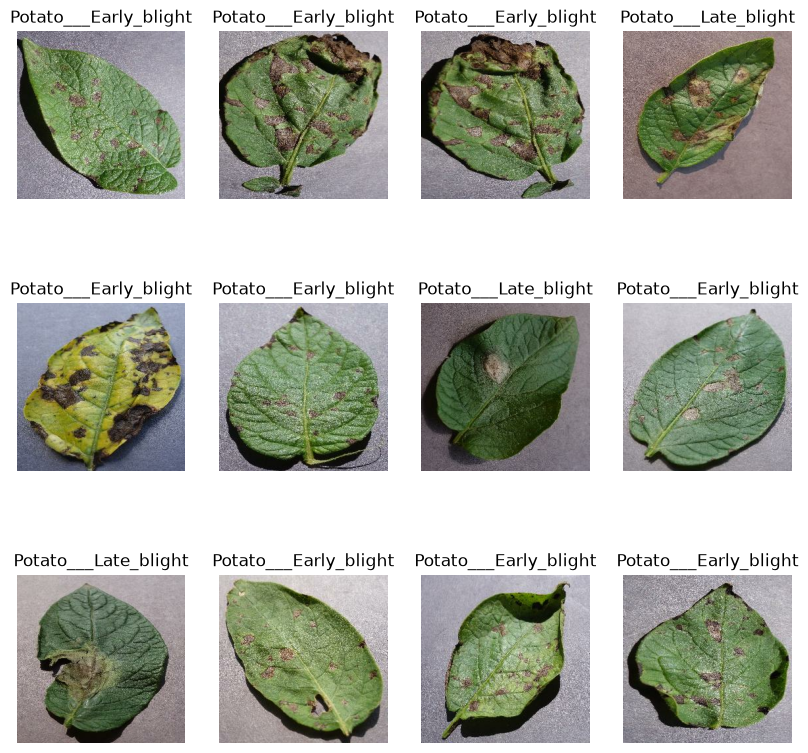

In [8]:
plt.figure(figsize=(10, 10))
for image_batch, labels_batch in dataset.take(1):
    for i in range(12):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.title(class_names[labels_batch[i]])
        plt.axis("off")

### Function to Split Dataset

Dataset should be bifurcated into 3 subsets, namely:
1. Training: Dataset to be used while training
2. Validation: Dataset to be tested against while training
3. Test: Dataset to be tested against after we trained a model

In [9]:
len(dataset)

68

In [10]:
train_size = 0.8
len(dataset)*train_size

54.400000000000006

In [11]:
train_ds = dataset.take(54)
len(train_ds)

54

In [12]:
test_ds = dataset.skip(54)
len(test_ds)

14

In [13]:
val_size=0.1
len(dataset)*val_size

6.800000000000001

In [14]:
val_ds = test_ds.take(6)
len(val_ds)

6

In [15]:
test_ds = test_ds.skip(6)
len(test_ds)

8

In [17]:
def get_dataset_partitions_tf(ds, train_split=0.8, val_split=0.1, test_split=0.1, shuffle=True, shuffle_size=10000):
    assert (train_split + test_split + val_split) == 1
    
    ds_size = len(ds)
    
    if shuffle:
        ds = ds.shuffle(shuffle_size, seed=12)
    
    train_size = int(train_split * ds_size)
    val_size = int(val_split * ds_size)
    
    train_ds = ds.take(train_size)    
    val_ds = ds.skip(train_size).take(val_size)
    test_ds = ds.skip(train_size).skip(val_size)
    
    return train_ds, val_ds, test_ds

In [18]:
train_ds, val_ds, test_ds = get_dataset_partitions_tf(dataset)

In [19]:
len(train_ds)

54

In [21]:
len(val_ds)

6

In [22]:
len(test_ds)

8

### Cache, Shuffle, and Prefetch the Dataset

In [23]:
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds = test_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)

## Building the Model

### Creating a Layer for Resizing and Normalization
Before we feed our images to network, we should be resizing it to the desired size. 
Moreover, to improve model performance, we should normalize the image pixel value (keeping them in range 0 and 1 by dividing by 256).
This should happen while training as well as inference. Hence we can add that as a layer in our Sequential Model.

You might be thinking why do we need to resize (256,256) image to again (256,256). You are right we don't need to but this will be useful when we are done with the training and start using the model for predictions. At that time somone can supply an image that is not (256,256) and this layer will resize it

In [28]:

# Create a sequence of image preprocessing layers
resize_and_rescale = tf.keras.Sequential([

    # Resize every image to IMAGE_SIZE × IMAGE_SIZE pixels
    layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),

    # Convert pixel values from the range 0–255 to 0–1
    layers.Rescaling(1.0 / 255),

])


### Data Augmentation
Data Augmentation is needed when we have less data, this boosts the accuracy of our model by augmenting the data.

In [31]:
data_augmentation = tf.keras.Sequential([
  layers.RandomFlip("horizontal_and_vertical"),
  layers.RandomRotation(0.2),
])

#### Applying Data Augmentation to Train Dataset

In [32]:
train_ds = train_ds.map(
    lambda x, y: (data_augmentation(x, training=True), y)
).prefetch(buffer_size=tf.data.AUTOTUNE)



### Model Architecture
We use a CNN coupled with a Softmax activation in the output layer. We also add the initial layers for resizing, normalization and Data Augmentation.

**We are going to use convolutional neural network (CNN) here. CNN is popular for image classification tasks. Watch below video to understand fundamentals of CNN**

In [33]:
input_shape = (BATCH_SIZE, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
n_classes = 3

model = models.Sequential([
    resize_and_rescale,
    layers.Conv2D(32, kernel_size = (3,3), activation='relu', input_shape=input_shape),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64,  kernel_size = (3,3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64,  kernel_size = (3,3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(n_classes, activation='softmax'),
])

model.build(input_shape=input_shape)

c:\Potato_Disease_CNN\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [34]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (32, 256, 256, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (32, 254, 254, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (32, 127, 127, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (32, 125, 125, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (32, 62, 62, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (32, 60, 60, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (32, 30, 30, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (32, 28, 28, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (32, 14, 14, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (32, 12, 12, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (32, 6, 6, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (32, 4, 4, 64)         │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (32, 2, 2, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (32, 256)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (32, 64)               │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (32, 3)                │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 183,747 (717.76 KB)

 Trainable params: 183,747 (717.76 KB)

 Non-trainable params: 0 (0.00 B)

### Compiling the Model
We use `adam` Optimizer, `SparseCategoricalCrossentropy` for losses, `accuracy` as a metric

In [36]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

In [38]:
history = model.fit(
    train_ds,
    batch_size=BATCH_SIZE,
    validation_data=val_ds,
    verbose=1,
    epochs=50,
)

Epoch 1/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 76s 1s/step - accuracy: 0.9554 - loss: 0.1130 - val_accuracy: 0.8333 - val_loss: 0.5171
Epoch 2/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 74s 1s/step - accuracy: 0.9641 - loss: 0.1010 - val_accuracy: 0.9167 - val_loss: 0.2504
Epoch 3/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 77s 1s/step - accuracy: 0.9606 - loss: 0.0926 - val_accuracy: 0.9427 - val_loss: 0.1311
Epoch 4/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 77s 1s/step - accuracy: 0.9792 - loss: 0.0537 - val_accuracy: 0.9323 - val_loss: 0.2204
Epoch 5/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 62s 1s/step - accuracy: 0.9647 - loss: 0.0998 - val_accuracy: 0.9010 - val_loss: 0.2667
Epoch 6/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.9676 - loss: 0.0855 - val_accuracy: 0.9635 - val_loss: 0.1060
Epoch 7/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 55s 1s/step - accuracy: 0.9774 - loss: 0.0583 - val_accuracy: 0.9531 - val_loss: 0.1501
Epoch 8/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 1527s 29s/step - accuracy: 0.9815 - loss: 0.0482 - val_accuracy: 0.9583 - val_lo

In [57]:
# Evaluate the trained model on validation images
loss, accuracy = model.evaluate(val_ds)

# Display the evaluation results
print(f"Validation Loss: {loss:.4f}")
print(f"Validation Accuracy: {accuracy * 100:.2f}%")

6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 322ms/step - accuracy: 0.9688 - loss: 0.1124
Validation Loss: 0.1124
Validation Accuracy: 96.88%


In [39]:
scores = model.evaluate(test_ds)

8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 252ms/step - accuracy: 0.9688 - loss: 0.0745


**You can see above that we get 96.88% accuracy for our test dataset. This is considered to be a pretty good accuracy**

In [40]:
scores

[0.0744866132736206, 0.96875]

Scores is just a list containing loss and accuracy value

### Plotting the Accuracy and Loss Curves

In [41]:
history

In [42]:
history.params

{'verbose': 1, 'epochs': 50, 'steps': 54}

In [43]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

**loss, accuracy, val loss etc are a python list containing values of loss, accuracy etc at the end of each epoch**

In [44]:
type(history.history['loss'])

list

In [45]:
len(history.history['loss'])

50

In [46]:
history.history['loss'][:5] # show loss for first 5 epochs

[0.11296529322862625,
 0.10103953629732132,
 0.0926273986697197,
 0.053704634308815,
 0.0998249426484108]

In [47]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

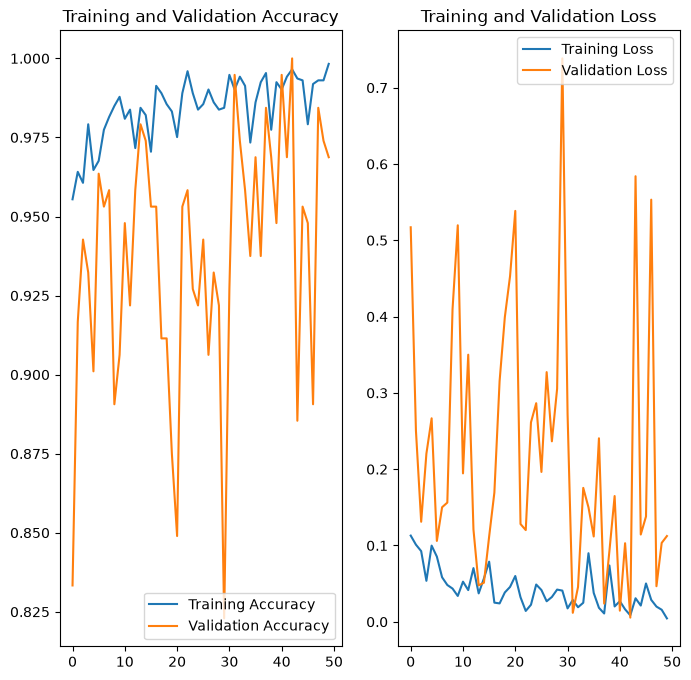

In [48]:
plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(range(EPOCHS), acc, label='Training Accuracy')
plt.plot(range(EPOCHS), val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(range(EPOCHS), loss, label='Training Loss')
plt.plot(range(EPOCHS), val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

### Run prediction on a sample image

first image to predict
actual label: Potato___Late_blight
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 730ms/step
predicted label: Potato___Late_blight


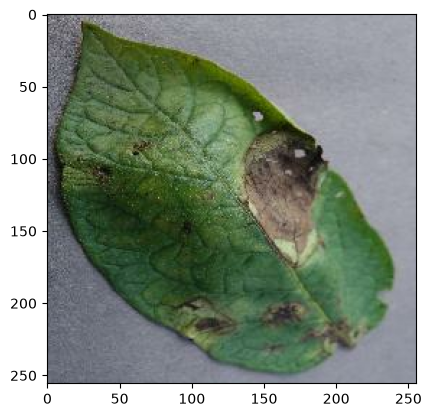

In [49]:
import numpy as np
for images_batch, labels_batch in test_ds.take(1):
    
    first_image = images_batch[0].numpy().astype('uint8')
    first_label = labels_batch[0].numpy()
    
    print("first image to predict")
    plt.imshow(first_image)
    print("actual label:",class_names[first_label])
    
    batch_prediction = model.predict(images_batch)
    print("predicted label:",class_names[np.argmax(batch_prediction[0])])

### Write a function for inference

In [50]:
def predict(model, img):
    img_array = tf.keras.preprocessing.image.img_to_array(images[i].numpy())
    img_array = tf.expand_dims(img_array, 0)

    predictions = model.predict(img_array)

    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = round(100 * (np.max(predictions[0])), 2)
    return predicted_class, confidence

**Now run inference on few sample images**

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 366ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step


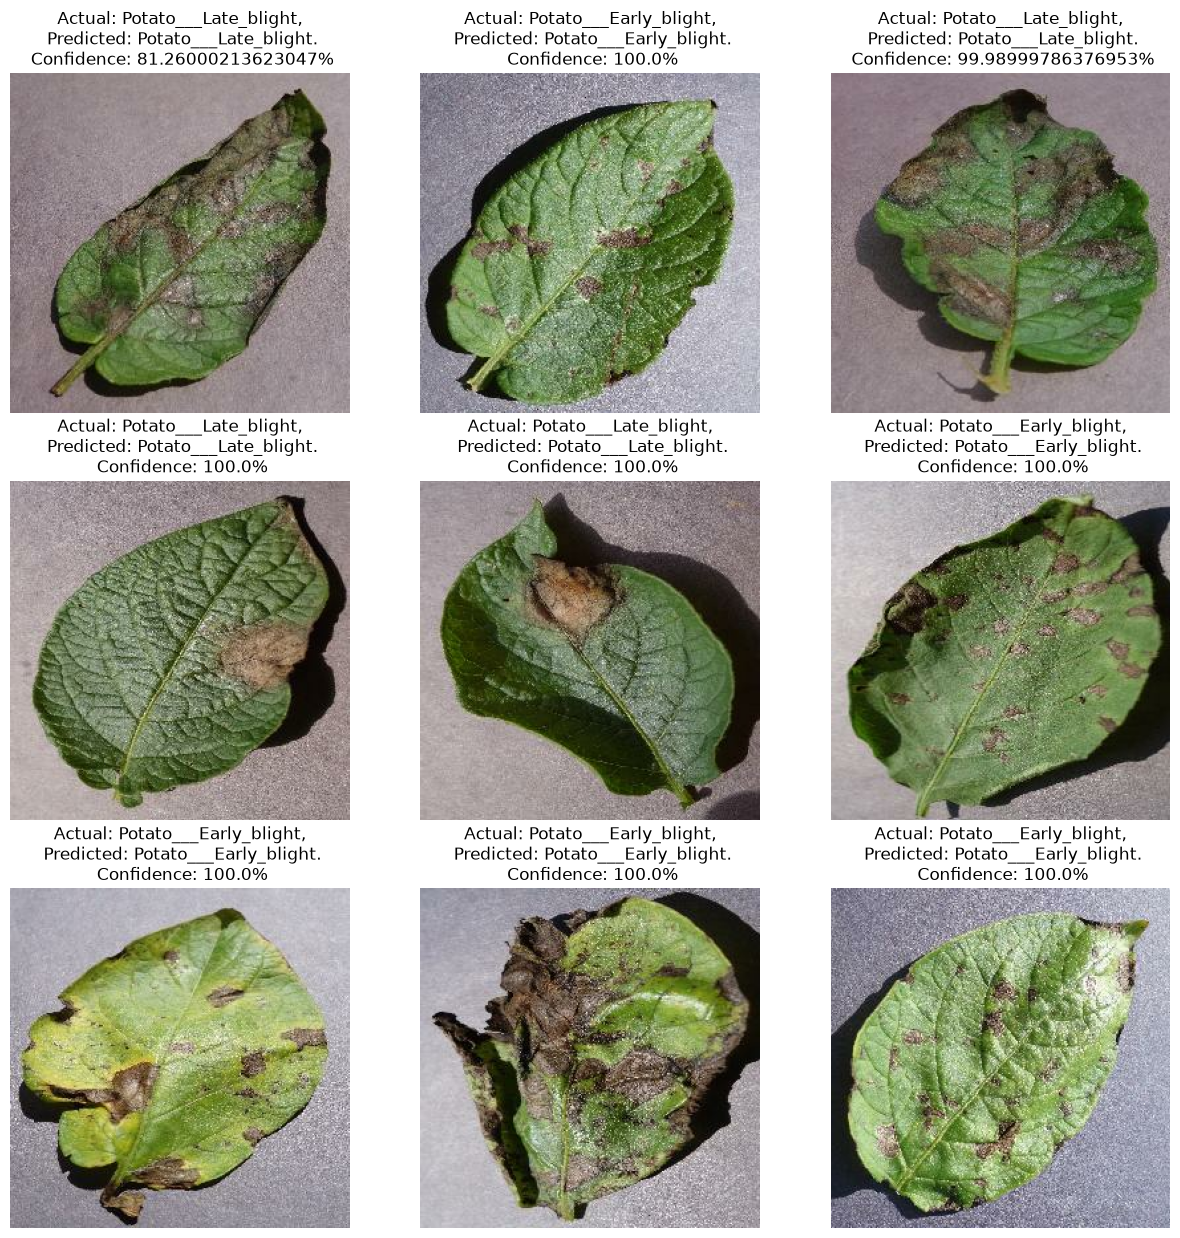

In [51]:
plt.figure(figsize=(15, 15))
for images, labels in test_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        
        predicted_class, confidence = predict(model, images[i].numpy())
        actual_class = class_names[labels[i]] 
        
        plt.title(f"Actual: {actual_class},\n Predicted: {predicted_class}.\n Confidence: {confidence}%")
        
        plt.axis("off")

### Saving the Model
We append the model to the list of models as a new version

In [54]:

import os  # Work with folders and file paths

# Create a models folder in the current project directory
os.makedirs("models", exist_ok=True)

# Confirm the folder was created
print("Models folder exists:", os.path.isdir("models"))


Models folder exists: True


In [56]:

import os  # Helps create and join file paths

# Build a save path inside the current project folder
save_path = os.path.join(os.getcwd(), "trained_potato_model.h5")

# Save the trained model to this location
model.save(save_path)

# Display the full path of the saved model
print("Model saved successfully:", save_path)


Model saved successfully: c:\Potato_Disease_CNN\trained_potato_model.h5


In [1]:
import os

# Check whether your saved model exists
model_path = os.path.join(os.getcwd(), "trained_potato_model.h5")

print("Model file exists:", os.path.isfile(model_path))
print("Model path:", model_path)

Model file exists: True
Model path: c:\Potato_Disease_CNN\trained_potato_model.h5


In [1]:

import tensorflow as tf
import os

model_path = r"C:\Potato_Disease_CNN\trained_potato_model.h5"
export_path = r"C:\Potato_Disease_CNN\potatoes_model\1"

model = tf.keras.models.load_model(model_path)

os.makedirs(export_path, exist_ok=True)

model.export(export_path)

print("Model exported successfully!")
print("Export path:", export_path)


INFO:tensorflow:Assets written to: C:\Potato_Disease_CNN\potatoes_model\1\assets


INFO:tensorflow:Assets written to: C:\Potato_Disease_CNN\potatoes_model\1\assets


Saved artifact at 'C:\Potato_Disease_CNN\potatoes_model\1'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  1952202084176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1952202084944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1952202084368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1952202086864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1952202085712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1952202088208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1952202086480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1952202087440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1952202087824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1952202085520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  19522020889

In [2]:

import requests
import numpy as np
from PIL import Image
from pathlib import Path

# Change this to your actual test image path
image_path = Path(r"C:\Potato_Disease_CNN\test\Potato___Early_blight")

# Find the first image in the folder
image_files = list(image_path.glob("*"))

print("Images found:", len(image_files))


Images found: 0


In [3]:

from pathlib import Path

base_path = Path(r"C:\Potato_Disease_CNN")

for item in base_path.iterdir():
    print(item.name, "—", "Folder" if item.is_dir() else "File")


.venv — Folder
models — Folder
PlantVillage — Folder
potato-disease-classification-model.ipynb — File
potatoes_model — Folder
potato_disease_classification.ipynb — File
trained_potato_model.h5 — File


Find a potato leaf image

In [4]:

from pathlib import Path

dataset_path = Path(r"C:\Potato_Disease_CNN\PlantVillage")

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}
image_files = [
    p for p in dataset_path.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Total images found:", len(image_files))

if image_files:
    print("First image:", image_files[0])


Total images found: 2152
First image: C:\Potato_Disease_CNN\PlantVillage\Potato___Early_blight\001187a0-57ab-4329-baff-e7246a9edeb0___RS_Early.B 8178.JPG


Display the image before sending it

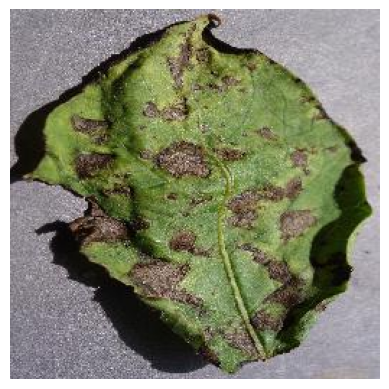

Image path: C:\Potato_Disease_CNN\PlantVillage\Potato___Early_blight\001187a0-57ab-4329-baff-e7246a9edeb0___RS_Early.B 8178.JPG
Image size: (256, 256)
Image mode: RGB


In [5]:

from PIL import Image
import matplotlib.pyplot as plt

# Select the first image found in our dataset
image_path = image_files[0]

# Open the image
image = Image.open(image_path)

# Display the image
plt.imshow(image)
plt.axis("off")
plt.show()

# Print image details
print("Image path:", image_path)
print("Image size:", image.size)
print("Image mode:", image.mode)


Prepare the image and send it to TensorFlow Serving

In [6]:

import requests
import numpy as np
from PIL import Image

# Step 1: Convert the image into a NumPy array
image_array = np.array(image).astype(np.float32)

# Step 2: Add the batch dimension
image_batch = np.expand_dims(image_array, axis=0)

print("Image batch shape:", image_batch.shape)

# Step 3: Prepare the TensorFlow Serving request
url = "http://localhost:8501/v1/models/potatoes_model:predict"

request_data = {
    "instances": image_batch.tolist()
}

# Step 4: Send the image to the model
response = requests.post(url, json=request_data, timeout=60)

print("HTTP status:", response.status_code)

# Step 5: Display the prediction scores
response.raise_for_status()
result = response.json()

predictions = np.array(result["predictions"][0])

class_names = ["Early Blight", "Late Blight", "Healthy"]

print("Prediction scores:", predictions)
print("Predicted class:", class_names[np.argmax(predictions)])


Image batch shape: (1, 256, 256, 3)
HTTP status: 200
Prediction scores: [1.00000000e+00 1.36175395e-14 1.44976900e-27]
Predicted class: Early Blight


Display all three class scores clearly

In [7]:

for class_name, score in zip(class_names, predictions):
    print(f"{class_name}: {score * 100:.6f}%")


Early Blight: 100.000000%
Late Blight: 0.000000%
Healthy: 0.000000%


Install FastAPI and its required packages

In [8]:
%pip install fastapi uvicorn python-multipart requests pillow

  Using cached uvicorn-0.54.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached python_multipart-0.0.32-py3-none-any.whl.metadata (2.1 kB)
  Using cached starlette-1.8.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached typing_inspection-0.4.4-py3-none-any.whl.metadata (2.6 kB)
  Using cached annotated_doc-0.0.5-py3-none-any.whl.metadata (6.5 kB)
  Using cached opentelemetry_api-1.45.1-py3-none-any.whl.metadata (1.4 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached annotated_types-0.8.0-py3-none-any.whl.metadata (15 kB)
Using cached uvicorn-0.54.0-py3-none-any.whl (87 kB)
Using cached python_multipart-0.0.32-py3-none-any.whl (30 kB)
Using cached annotated_doc-0.0.5-py3-none-any.whl (5.3 kB)
Using cached click-8.5.0-py3-none-any.whl (125 kB)
Using cached opentelemetry_api-1.45.1-py3-none-any.whl (60 kB)
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   -------------- ------------------------- 0.8/2.2 MB 4.2 MB/s eta 0:00:01
   -------